In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import shutil
from scipy.signal import savgol_filter
import pandas as pd
from pathlib import Path
import re
import pyarrow.feather as feather
import sys
import joblib

from random import randint

### Set global variables

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVE_DIR = Path("~/ECM_mod_output/").expanduser()
LYAP_DIR = Path(SAVE_DIR,'UMAP/ODE_embeddings')
LYAP_DIR.mkdir(parents=True, exist_ok=True)
EMBED_DIR = Path('../../Data','UMAP_embedding_ode') # location of saved embedding files for each condition
SET_JPARAM = True

USE_ORIGINAL = False # set to true to automatically download the original data from Dropbox

rcParams.update({'figure.autolayout': True})

sys_type = sys.platform
if sys_type == 'darwin':
    sys_name = 'mac'
elif sys_type == 'win32': 
    sys_name = 'win'
elif sys_type == 'linux': 
    sys_name = 'linux'

### Load UMAP embedding of Lyapunov data
UMAP embeddings should be `LYAP_DIR`. If they are not detected, they will be downloaded automatically.  

NOTE: Compressed LYAP_DIR data is ~50 MB. 

In [3]:
LYAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f and 'embedding_' in f and 'psoparam_2' in f]   
if len(LYAP_filepaths) < 2000 or USE_ORIGINAL:
    print(f'Could not find Lyapnunov data; downloading to {LYAP_DIR}')
    !wget -O LYAP.zip 'https://www.dropbox.com/scl/fi/fxvzth5roj9fwvakjnlzl/Lyap_analysis.zip?rlkey=neodaaajtyk4lt1boq6bhoxnr&dl=1'
    !unzip LYAP.zip
    shutil.rmtree(LYAP_DIR)
    shutil.move('./Lyap_analysis/', SAVE_DIR)
    os.remove('./LYAP.zip')
    LYAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f and 'embedding_' in f and 'psoparam' in f]   

LYAP_filepaths.sort()

In [4]:
len(LYAP_filepaths)

2000

In [36]:
filenames_erl = [f for f in LYAP_filepaths if 'ERL' in f]
filenames_erl.sort()

if Path(LYAP_DIR,'ERL_pso_param_2_IMT.csv').exists():
    ode_divs_erl = np.genfromtxt(str(Path(LYAP_DIR,'ERL_pso_param_2_IMT.csv')), delimiter=',')
# else:
#     ode_divs_erl = np.genfromtxt(Path('../../Data/Lyapunov_data/erl_IMT.csv'), delimiter=',')

if Path(SAVE_DIR,'lyap_erl_PSO.csv').exists():
    lyap_erl = np.genfromtxt(Path(SAVE_DIR,'lyap_erl_PSO.csv'), delimiter=',')
# else:
#     lyap_erl = np.genfromtxt(Path('../../Data/Lyapunov_data/lyap_erl.csv'), delimiter=',')

In [35]:
filenames_dmso = [f for f in LYAP_filepaths if 'DMSO' in f]
filenames_dmso.sort()

if Path(LYAP_DIR,'DMSO_pso_param_2_IMT.csv').exists():
    ode_divs_dmso = np.genfromtxt(str(Path(LYAP_DIR,'DMSO_pso_param_2_IMT.csv')), delimiter=',')
# else:
#     ode_divs_dmso = np.genfromtxt(Path('../../Data/Lyapunov_data/dmso_IMT.csv'), delimiter=',')

if Path(SAVE_DIR,'lyap_dmso_PSO.csv').exists():
    lyap_dmso = np.genfromtxt(Path(SAVE_DIR,'lyap_dmso_PSO.csv'), delimiter=',')
# else:
#     lyap_dmso = np.genfromtxt(Path('../../Data/Lyapunov_data/lyap_dmso.csv'), delimiter=',')

In [17]:
assert len(filenames_dmso) == len(filenames_erl) == 1000

In [20]:
all_divs = np.concatenate((ode_divs_erl, ode_divs_dmso))
ode_max = max(all_divs)
ode_min = min(all_divs)


In [21]:
tmp_emb = np.genfromtxt(filenames_erl[600], delimiter=',')
tmp_l = len(tmp_emb)

In [22]:
size = (8,4)
xmin = -10
xmax = 15
ymin = 0
ymax = 18
wid = 1

In [23]:
norm = plt.Normalize(ode_min, ode_max)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

x_lin = np.arange(0,1,0.001)

C:\Users\olesk\AppData\Local\Temp\ipykernel_12268\3296897538.py:87: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a_fn, bbox_inches='tight')


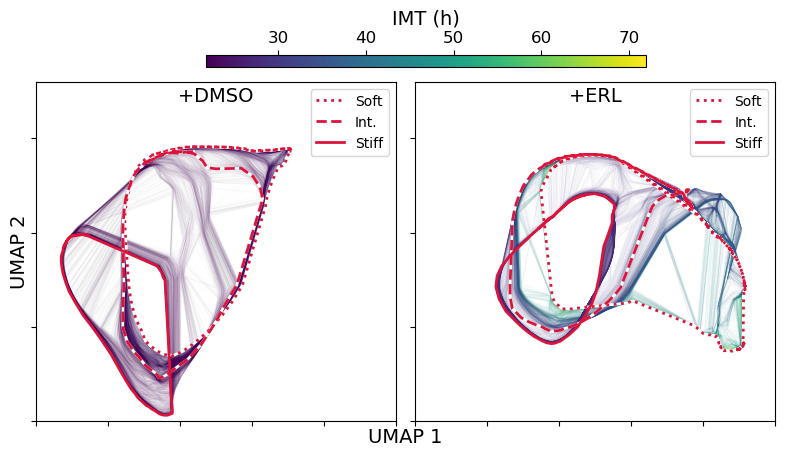

In [25]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(ode_divs_dmso[ii])), lw=0.01, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(ode_divs_erl[ii])), lw=0.01, alpha=0.5)
    ii+=1
    
    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
# tmp_l = int(len(tmp_emb))
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])

tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)    

axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', location='top', label='IMT (h)')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVE_DIR, 'fig4a_supp.png')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [26]:
norm = plt.Normalize(-0.04, 0)
cm = plt.cm.summer_r
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

### Downsample ODE trajectories to 1/10 (100 trajectories)

In [27]:
filenames_dmso_100 = filenames_dmso[0::10]
filenames_erl_100 = filenames_erl[0::10]

In [28]:
len(filenames_erl_100)

100

C:\Users\olesk\AppData\Local\Temp\ipykernel_12268\3469430875.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a_fn, bbox_inches='tight')


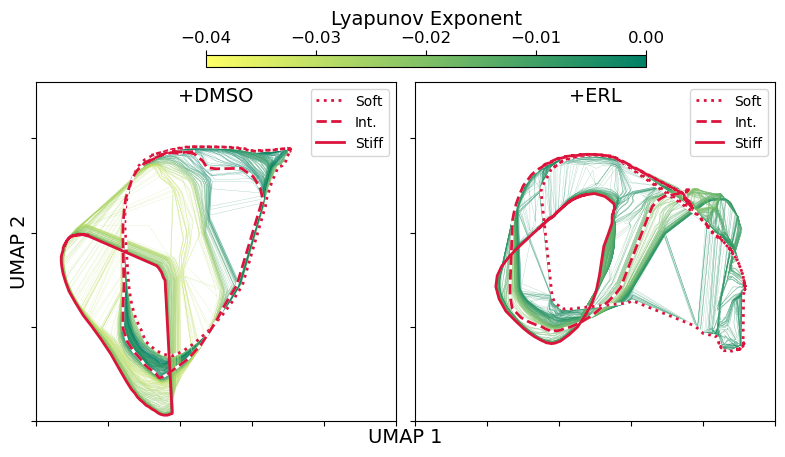

In [29]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_dmso[ii])), lw=0.2, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_erl[ii])), lw=0.2, alpha=0.5)
    ii+=1
    

    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])
    


tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)     


axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, ticks=[-0.04, -0.03, -0.02, -0.01, 0], 
             orientation='horizontal', location='top', label='Lyapunov Exponent')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVE_DIR, 'fig4a_lyap_supp.png')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [30]:
ode_divs_erl[0]

71.94

In [31]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 24,
         'axes.titlesize': 24,
         'axes.edgecolor': "black",
         'xtick.labelsize': 20,
         'ytick.labelsize': 20}
plt.rcParams.update(params)

(-0.05, 0.02)

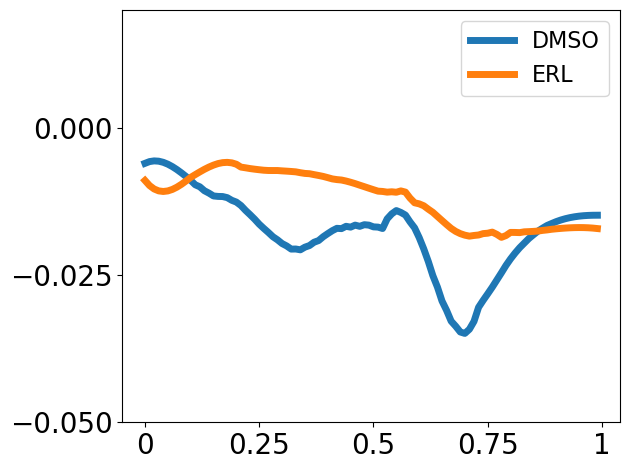

In [37]:
plt.plot(lyap_dmso, label="DMSO", lw=5)
plt.plot(lyap_erl, label='ERL', lw=5)
plt.legend(fontsize=16)
locs, labels = plt.xticks() 
plt.xticks([0, 25, 50, 75, 100], [0, 0.25, 0.5, 0.75, 1])
plt.yticks([-0.05, -0.025, 0])

plt.ylim(-0.05, 0.02)

### Load and plot ODE trajectories

In [40]:
output_from = 1 # 1: original, 2: PSO params, 3: 03_ECM_model_output.ipynb, 4: 04_Stoch_sims_for_UMAP.ipynb

if output_from == 1:
    embed_source = 'orig'
elif output_from == 2:
    embed_source = 'psoparams'
else:
    embed_source = f'from_0{output_from}'

if SET_JPARAM:
    all_embed_odes = joblib.load(Path(SAVE_DIR, f'all_embedding_ode_conds_{embed_source}_{sys_name}.sav'))
else:
    all_embed_odes = joblib.load(Path(SAVE_DIR, f'all_embedding_ode_conds_{sys_name}_{embed_source}.sav'))
all_embed_odes.shape

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\olesk\\ECM_mod_output\\all_embedding_ode_conds_orig_win.sav'

#### Define conditions and annotations

In [38]:
conds = ['0.0 DMSO', '0.3 DMSO', '0.5 DMSO', '0.75 DMSO', '1.0 DMSO','0.0 ERL', '0.3 ERL', '0.5 ERL', '0.75 ERL', '1.0 ERL',]
colors_blue = plt.cm.Blues(np.linspace(0,1,7))
colors_red = plt.cm.Reds(np.linspace(0,1,6))
cond_colors = [colors_blue[2], colors_blue[3], colors_blue[4], colors_blue[5], colors_blue[6], colors_red[1], colors_red[2], colors_red[3], colors_red[4], colors_red[5],]
conds_idx = [0,1,2,3,4,5,6,7,8,9,]
plot_ode_len = [120,100,0,100,60,150,0,80,0,60,]
line_type = ['-', '-', '-', '-', '-', '--', '--', '--', '--', '--',]


In [39]:
# plot parameters
trk_len = 2000 # length of ODE trajectories
size = (3,3)
l = trk_len
lw=2
fontsize = 7
embed_array = all_embed_odes

NameError: name 'all_embed_odes' is not defined

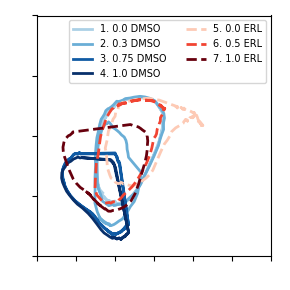

In [22]:
fig = plt.figure(figsize=size)

for i,x in enumerate([0,1,3,4,5,7,9,]):
    plt.plot(embed_array[x*l:x*l+plot_ode_len[x],0], 
             embed_array[x*l:x*l+plot_ode_len[x],1], 
             ls=line_type[x], lw=lw, alpha=1, color=cond_colors[x], label=f'{i+1}. {conds[x]}')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [0,1,2,3,4,5,6,]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], 
           loc="upper right", ncol=2, fontsize=fontsize)